Phase 1 (Extract)

In [148]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine, text

raw = pd.read_csv("../data/raw/owid-covid-data.csv")

df = raw.copy() #to avoid altering the original dataset and only work on copy
print(df.shape)

(429435, 67)


Phase 2 (EDA)

In [149]:
#Basic exploration
print(df.shape) #to check the number of rows and columns
print(df.columns.tolist()) #to see the column names
print(df.dtypes) #to see data types 
print(df.head()) #to see sample records (top 5)
print(df.describe().T) #for the summary statistics of dataset

(429435, 67)
['iso_code', 'continent', 'location', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'reproduction_rate', 'icu_patients', 'icu_patients_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'positive_rate', 'tests_per_case', 'tests_units', 'total_vaccinations', 'people_vaccinated', 'people_fully_vaccinated', 'total_boosters', 'new_vaccinations', 'new_vaccinations_smoothed', 'total_vaccinations_per_hundred', 'people_vaccinated_per_hundred', 'people_fully_vaccinated_per_hund

In [150]:
#Checkinf for unique values in important columns
print(df["location"].nunique(), "locations")
print(df["continent"].nunique(), "continents")
print(df["continent"].value_counts(dropna=False))   #to check suspicious rows
print(df["tests_units"].value_counts(dropna=False)) #to check categories

255 locations
6 continents
continent
Africa           95419
Europe           91031
Asia             84199
North America    68638
Oceania          40183
NaN              26525
South America    23440
Name: count, dtype: int64
tests_units
NaN                322647
tests performed     80099
people tested       16257
samples tested       9591
units unclear         841
Name: count, dtype: int64


In [151]:
#Missing values
#This particular line checks the percentage of null per column
#Through this, we can see which columns are mostly empty
print((df.isnull().mean() * 100).round(1).sort_values(ascending=False).head(15))

weekly_icu_admissions_per_million          97.4
weekly_icu_admissions                      97.4
excess_mortality_cumulative_per_million    96.9
excess_mortality                           96.9
excess_mortality_cumulative                96.9
excess_mortality_cumulative_absolute       96.9
weekly_hosp_admissions_per_million         94.3
weekly_hosp_admissions                     94.3
icu_patients                               90.9
icu_patients_per_million                   90.9
hosp_patients_per_million                  90.5
hosp_patients                              90.5
total_boosters_per_hundred                 87.5
total_boosters                             87.5
new_vaccinations                           83.5
dtype: float64


In [152]:
#Finding duplicates

#checks for rows that are entirely duplicates of other rows
print("Full duplicates: ", df.duplicated().sum()) 
#checks for duplicate countries and dates
print("Duplicate country+date: ", df.duplicated(subset=["iso_code", "date"]).sum())

Full duplicates:  0
Duplicate country+date:  7770


In [153]:
#To find locations that do not have a continent assigned to them 
print(df[df["continent"].isnull()]["location"].unique())  

<ArrowStringArray>
[                       'Africa',                          'Asia',
                        'Europe',           'European Union (27)',
         'High-income countries',          'Low-income countries',
 'Lower-middle-income countries',                 'North America',
                       'Oceania',                 'South America',
 'Upper-middle-income countries',                         'World']
Length: 12, dtype: str


In [154]:
#To check for invalid negative values in the new cases and new deaths columns
print("Negative new cases: ", (df["new_cases"] < 0).sum())
print("Negative new deaths: ", (df["new_deaths"] < 0).sum())

Negative new cases:  0
Negative new deaths:  0


In [155]:
#To check for extra spaces at the beginning or end of text in location column
print((df["location"] != df["location"].str.strip()).sum())

0


In [156]:
#To check for unusually large daily case counts
print(df["new_cases"].describe())
print(df.nlargest(5, "new_cases")[["location", "date", "new_cases"]])

count    4.101590e+05
mean     8.017360e+03
std      2.296649e+05
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      4.423623e+07
Name: new_cases, dtype: float64
                             location        date   new_cases
423814                          World  2022-12-25  44236227.0
21177                            Asia  2022-12-25  42142424.0
409223  Upper-middle-income countries  2022-12-25  40975782.0
74755                           China  2022-12-25  40475477.0
423821                          World  2023-01-01  27732700.0


In [157]:
#Creating a new dataframe with rows that do not have any missing values in continent column
countries_only = df[df["continent"].notnull()]

location
United States     103436829.0
China              99373219.0
India              45041748.0
France             38997490.0
Germany            38437756.0
Brazil             37511921.0
South Korea        34571873.0
Japan              33803572.0
Italy              26781078.0
United Kingdom     24974629.0
Name: total_cases, dtype: float64


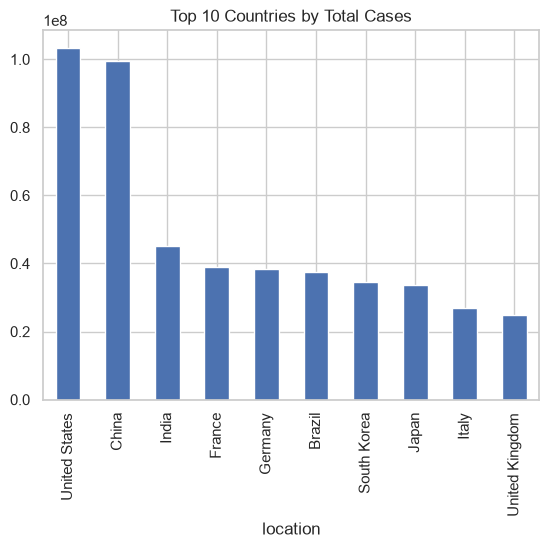

In [158]:
#to find the top 10 countires with the highest case counts
top10 = (countries_only.groupby("location")["total_cases"].max()
         .sort_values(ascending=False).head(10))
print(top10)
top10.plot(kind="bar", title="Top 10 Countries by Total Cases")
plt.show()

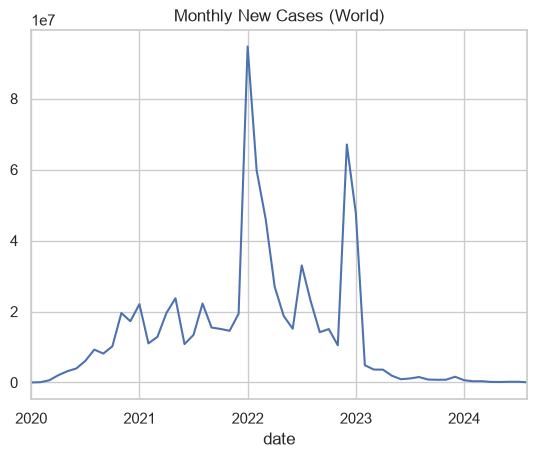

In [159]:
#To create a mothly trend of new cases over 4 years
tmp = countries_only.copy()
tmp["date"] = pd.to_datetime(tmp["date"])
monthly = tmp.groupby(tmp["date"].dt.to_period("M"))["new_cases"].sum()
monthly.plot(title="Monthly New Cases (World)")
plt.show()

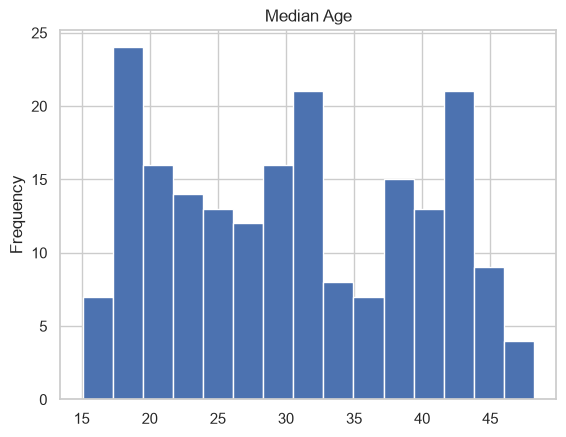

In [160]:
#to create a histogram of distribution of median age across the countries
countries_only.drop_duplicates("location")["median_age"].plot(kind="hist", bins=15, title="Median Age")
plt.show()

Phase 3 (Clean and Transform)

In [161]:
#to remove rows that do not have a continent assigned as we checked in Phase 2
#removing such rows helps us narrow down the analysis to specific countries rather than aggregate regions like "Europe"
df = df[df["continent"].notnull()].copy()

In [162]:
#to remove duplicate records where the same country has multiple rows for the same date
#this keeps the last occurrence of each country-date combination and avoids inflating total case numbers
df = df.drop_duplicates(subset=["iso_code", "date"], keep="last")

In [163]:
#to convert all dates into a uniform format understandable by pandas
df["date"] = pd.to_datetime(df["date"])

In [164]:
#to remove spaces from the beginning and end of location names
df["location"] = df["location"].str.strip()

In [165]:
#to handle missing values, negative numbers, and data types
#in this analysis, we are keeping the outliers as they can represent sudden surge in virus waves
df = df.sort_values(["iso_code", "date"]) #to sort data by countries and dates

for col in ["new_cases", "new_deaths"]: #to handle missing daily cases and death counts 
    df[col] = df[col].fillna(0).clip(lower=0).round().astype(int)

for col in ["total_cases", "total_deaths"]: #to handle cumulative total
    df[col] = df.groupby("iso_code")[col].ffill().fillna(0).astype("int64")

In [166]:
#to create new columns to classify data by year, month, and day
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["case_fatality_rate"] = (df["total_deaths"] / df["total_cases"].where(df["total_cases"] > 0) * 100).round(2)

In [167]:
#to separate the dataset into two dataframes to later operate on as two database tables
#also to remove unnecessary columns by only selecting what we need.
countries = df.groupby("iso_code").agg(
    location=("location", "first"),
    continent=("continent", "first"),
    population=("population", "first"),
    median_age=("median_age", "first"),
    gdp_per_capita=("gdp_per_capita", "first"),
    life_expectancy=("life_expectancy", "first"),
    hospital_beds_per_thousand=("hospital_beds_per_thousand", "first"),
).reset_index()
countries["population"] = countries["population"].astype("int64")

daily_cases = df[["iso_code", "date", "new_cases", "total_cases", "new_deaths", 
                  "total_deaths", "case_fatality_rate", "stringency_index", "year", "month"]]

In [168]:
#to replace case-fatality rates above 100% with missing values then prints the highest remaining rate
daily_cases = daily_cases.copy()
daily_cases.loc[daily_cases["case_fatality_rate"] > 100, "case_fatality_rate"] = None
print(daily_cases["case_fatality_rate"].max())  

100.0


In [169]:
#again, to create two other dataframes for vaccination and testing data
#also, to remove dates that have no vaccine/test data
vaccinations = df[["iso_code", "date", "total_vaccinations", "people_vaccinated",
                   "people_fully_vaccinated", "new_vaccinations"]].dropna(
    subset=["total_vaccinations", "people_vaccinated", "people_fully_vaccinated", "new_vaccinations"],
    how="all")

tests = df[["iso_code", "date", "total_tests", "new_tests", "positive_rate"]].dropna(
    subset=["total_tests", "new_tests", "positive_rate"], how="all")

In [170]:
#to store the new dataframes as csv files
countries.to_csv("../data/processed/countries.csv", index=False)
daily_cases.to_csv("../data/processed/daily_cases.csv", index=False)
vaccinations.to_csv("../data/processed/vaccinations.csv", index=False)
tests.to_csv("../data/processed/tests.csv", index=False)
print(countries.shape, daily_cases.shape, vaccinations.shape, tests.shape)

(243, 8) (401502, 10) (71206, 6) (100981, 5)


Phase 4 (Analysis and Insights)

In [171]:
#to combine daily_cases and countries tables into one dataframe
merged = daily_cases.merge(countries, on="iso_code")

In [ ]:
#Question 1
#to find 10 locations with the highest sum of reported new COVID-19 cases
q1 = merged.groupby("location")["new_cases"].sum().sort_values(ascending=False).head(10)
print(q1)

location
United States     103436829
China              99373219
India              45041748
France             38997490
Germany            38437756
Brazil             37511921
South Korea        34571873
Japan              33803572
Italy              26781078
United Kingdom     24974629
Name: new_cases, dtype: int64


In [ ]:
#Question 2
#to find the continent which had the highest total cases
q2 = merged.groupby("continent")["new_deaths"].sum().sort_values(ascending=False)
print(q2)

continent
Europe           2102377
North America    1671512
Asia             1637197
South America    1357619
Africa            259121
Oceania            33024
Name: new_deaths, dtype: int64


In [ ]:
#Question 3
#to find the five year-month combinations with highest total reported cases
q3 = merged.groupby(["year", "month"])["new_cases"].sum().sort_values(ascending=False).head(5)
print(q3)

year  month
2022  1        94694055
      12       67065865
      2        59758923
2023  1        47674026
2022  3        46082332
Name: new_cases, dtype: int64


In [ ]:
#Question 4
#to find the locations with highest percentage of deaths among locations that have over 1 million cases
q4 = merged.groupby("location").agg(cases=("new_cases", "sum"), deaths=("new_deaths", "sum"))
q4 = q4[q4["cases"] > 1_000_000]
q4["fatality_pct"] = (q4["deaths"] / q4["cases"] * 100).round(2)
print(q4.sort_values("fatality_pct", ascending=False).head(10))

                cases  deaths  fatality_pct
location                                   
Peru          4526977  220975          4.88
Mexico        7619458  334551          4.39
Ecuador       1079039   36050          3.34
Bulgaria      1329988   38700          2.91
Tunisia       1153361   29423          2.55
South Africa  4072765  102595          2.52
Indonesia     6829399  162063          2.37
Colombia      6391876  142727          2.23
Hungary       2230800   49053          2.20
Ukraine       5532777  109920          1.99


In [ ]:
#Question 5
#to find 10 countries with the highest percentage of population fully vaccinated
q5 = vaccinations.groupby("iso_code")["people_fully_vaccinated"].max().reset_index()
q5 = q5.merge(countries, on="iso_code")
q5["pct_fully_vaccinated"] = (q5["people_fully_vaccinated"] / q5["population"] * 100).round(1)
print(q5.sort_values("pct_fully_vaccinated", ascending=False)[["location", "pct_fully_vaccinated"]].head(10))

                 location  pct_fully_vaccinated
71              Gibraltar                 126.9
196               Tokelau                 116.4
166                 Qatar                 105.8
6    United Arab Emirates                 103.7
157              Pitcairn                 100.0
29                 Brunei                  99.5
118                 Macao                  92.4
173             Singapore                  90.8
81              Hong Kong                  90.8
35                  Chile                  90.3


Phase 5 (Database Design) in "schema.sql"

Phase 6 (Load into PostgreSQL)

In [ ]:
#to connect and create the tables
engine = create_engine("postgresql+psycopg2://prijinagurung@localhost:5432/covid_db")

with engine.begin() as conn:
    conn.execute(text(open("../sql/schema.sql").read()))

In [ ]:
#to load the data
countries.to_sql("countries", engine, if_exists="append", index=False)
daily_cases.to_sql("daily_cases", engine, if_exists="append", index=False, chunksize=5000, method="multi")
vaccinations.to_sql("vaccinations", engine, if_exists="append", index=False, chunksize=5000, method="multi")
tests.to_sql("tests", engine, if_exists="append", index=False, chunksize=5000, method="multi")

100981

In [179]:
#to check the counts
for t in ["countries", "daily_cases", "vaccinations", "tests"]:
    print(t, pd.read_sql(f"SELECT COUNT(*) FROM {t}", engine).iloc[0, 0])

countries 243
daily_cases 401502
vaccinations 71206
tests 100981
